# Color-only background removal (QS2)
One image, shown **before / after** each transformation. At the end: predicted mask vs ground truth.

In [30]:
import os
import cv2
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

# ---- CONFIG: change these ----
DATA_DIR = Path().resolve().parent / 'data'
BBDD_DIR = DATA_DIR / 'BBDD'
QSD2 = DATA_DIR / 'qsd2_w2'
IMG_PATH = QSD2 / "00014.jpg"
GT_PATH  = QSD2 / "00014.png"   # ground-truth mask (white = painting)
BORDER = 10          # px strip used to model the background
BLUR_KSIZE = 7
PROJ_FRAC = 0.5      # row/col is "painting" if >50% of it is foreground


In [31]:
def show_pair(before, after, t_before="Before", t_after="After", cmap_b=None, cmap_a=None, suptitle=None):
    fig, ax = plt.subplots(1, 2, figsize=(11, 6))
    ax[0].imshow(before, cmap=cmap_b); ax[0].set_title(t_before)
    ax[1].imshow(after, cmap=cmap_a);  ax[1].set_title(t_after)
    for a in ax: a.axis("off")
    if suptitle: fig.suptitle(suptitle, fontsize=14)
    plt.tight_layout(); plt.show()

rgb = lambda bgr: cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


## 0. Input image

shape: (580, 584, 3)


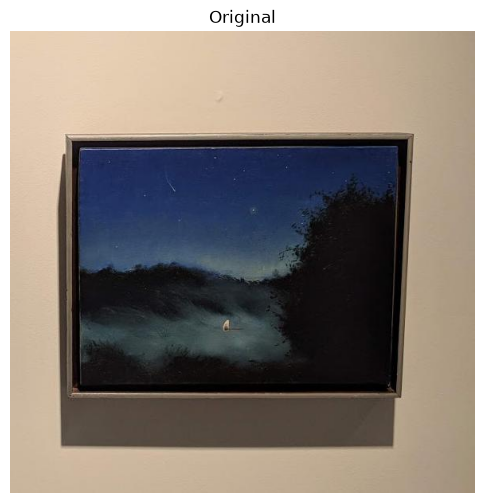

In [32]:
img = cv2.imread(IMG_PATH)
assert img is not None, f"Could not read {IMG_PATH}"
H, W = img.shape[:2]
print("shape:", img.shape)
plt.figure(figsize=(6, 7)); plt.imshow(rgb(img)); plt.axis("off"); plt.title("Original"); plt.show()


## 1. Preprocessing: Gaussian blur
Removes texture / noise so the color statistics are smoother.

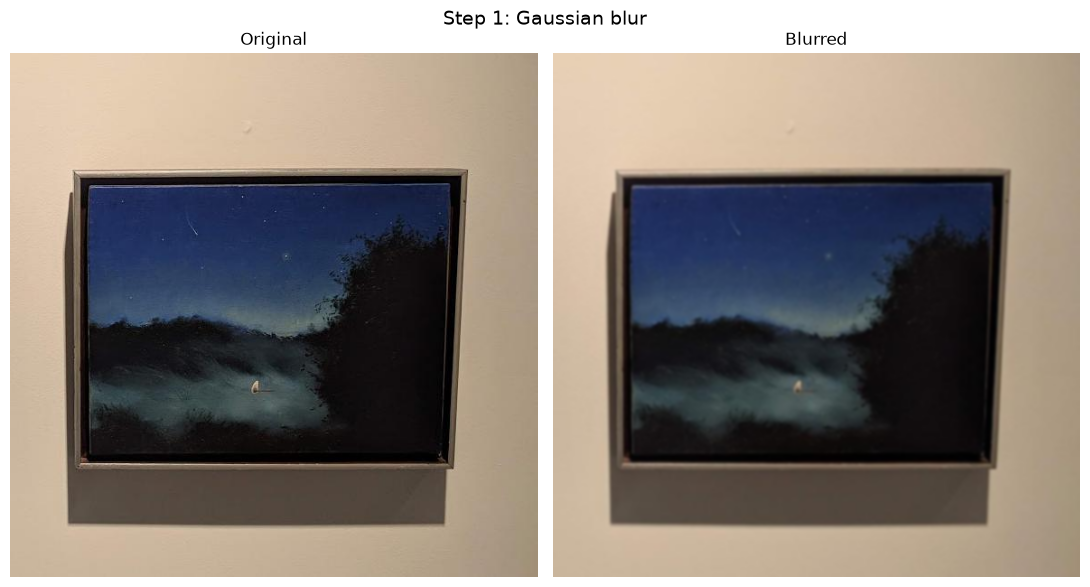

In [33]:
blur = cv2.GaussianBlur(img, (BLUR_KSIZE, BLUR_KSIZE), 0)
show_pair(rgb(img), rgb(blur), "Original", "Blurred", suptitle="Step 1: Gaussian blur")


## 2. Color space: BGR → Lab
Shown as the three Lab channels (L = lightness, a / b = chroma).

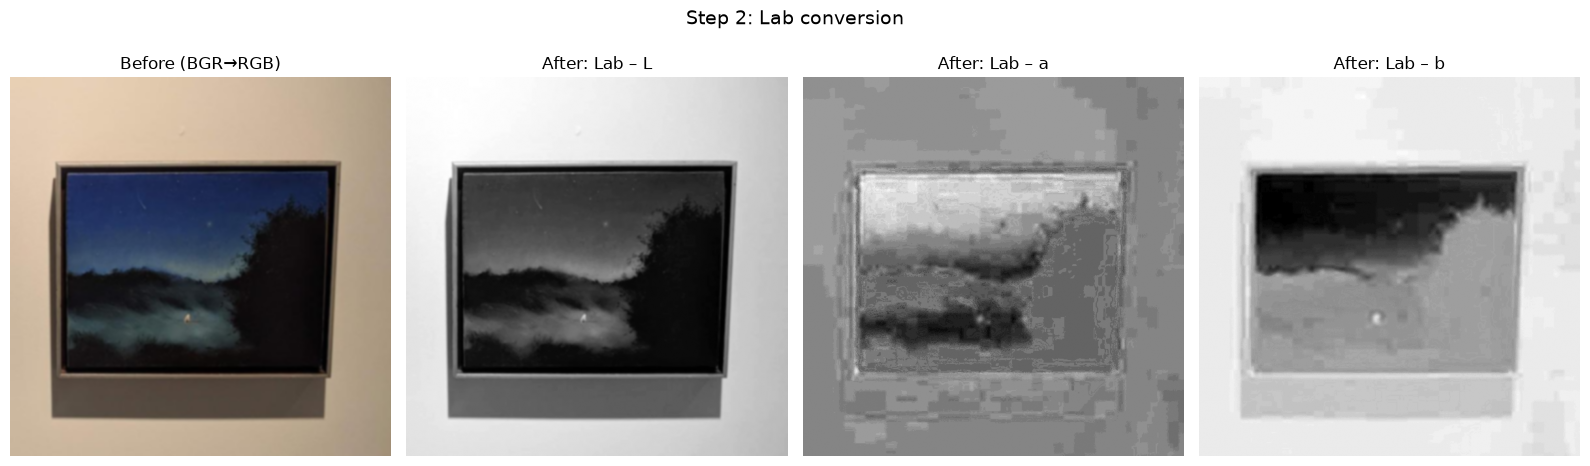

In [34]:
lab = cv2.cvtColor(blur, cv2.COLOR_BGR2LAB)
fig, ax = plt.subplots(1, 4, figsize=(16, 5))
ax[0].imshow(rgb(blur)); ax[0].set_title("Before (BGR→RGB)")
for i, n in enumerate(["L", "a", "b"]):
    ax[i + 1].imshow(lab[..., i], cmap="gray"); ax[i + 1].set_title(f"After: Lab – {n}")
for a in ax: a.axis("off")
fig.suptitle("Step 2: Lab conversion", fontsize=14); plt.tight_layout(); plt.show()


## 3. Background model from the border strip
Median color + robust covariance of the 10 px frame around the image.

Background median (L, a, b): [191. 131. 143.]
Background covariance:
 [[3.0857e+02 9.7900e+00 1.1560e+01]
 [9.7900e+00 1.7500e+00 1.3000e-01]
 [1.1560e+01 1.3000e-01 2.0100e+00]]


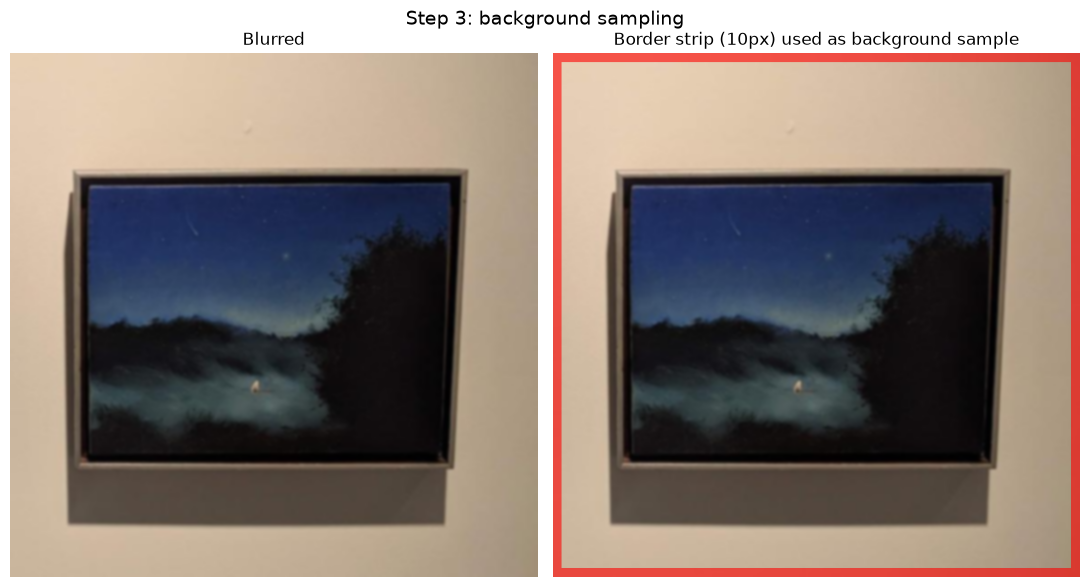

In [35]:
def border_mask(h, w, b=BORDER):
    m = np.zeros((h, w), bool)
    m[:b] = m[h - b:] = True
    m[:, :b] = m[:, w - b:] = True
    return m

bm = border_mask(H, W)
px = lab[bm].astype(np.float32)
med = np.median(px, axis=0)
d = np.linalg.norm(px - med, axis=1)
inliers = px[d < np.percentile(d, 90)]          # drop outliers (labels, shadows)
cov = np.cov(inliers.T) + np.eye(3)             # regularised
icov = np.linalg.inv(cov)
print("Background median (L, a, b):", med)
print("Background covariance:\n", np.round(cov, 2))

overlay = rgb(blur).copy()
overlay[bm] = (0.4 * overlay[bm] + 0.6 * np.array([255, 0, 0])).astype(np.uint8)
show_pair(rgb(blur), overlay, "Blurred", f"Border strip ({BORDER}px) used as background sample",
          suptitle="Step 3: background sampling")


## 4. Distance to the background model (Mahalanobis)

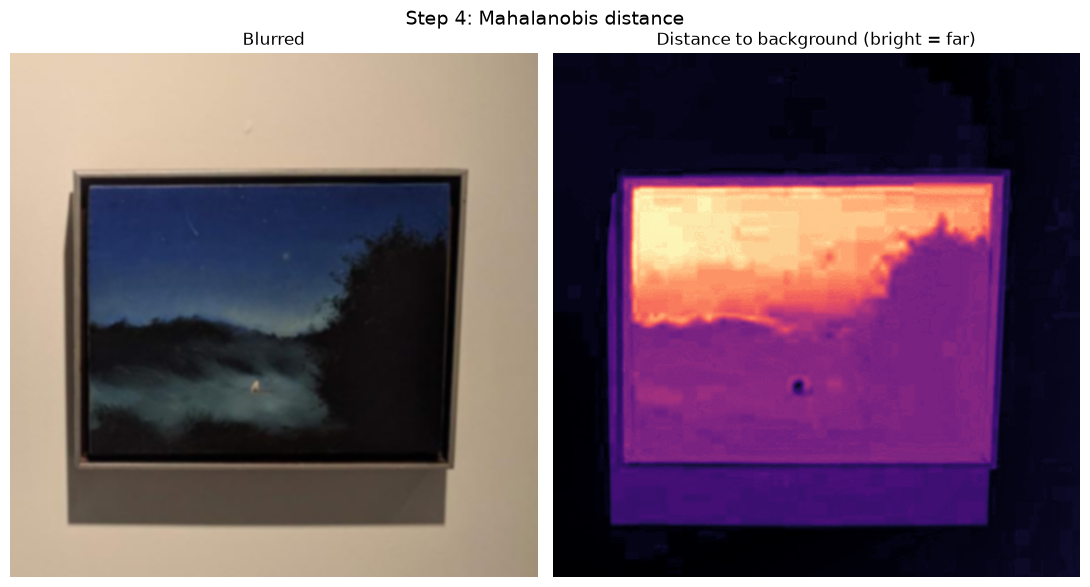

In [36]:
diff = lab.reshape(-1, 3).astype(np.float32) - med
dist = np.sqrt(np.maximum(np.einsum("ij,jk,ik->i", diff, icov, diff), 0)).reshape(H, W)
dist_u8 = cv2.normalize(dist, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
show_pair(rgb(blur), dist_u8, "Blurred", "Distance to background (bright = far)",
          cmap_a="magma", suptitle="Step 4: Mahalanobis distance")


## 5. Otsu threshold → raw foreground mask

Otsu threshold: 122.0


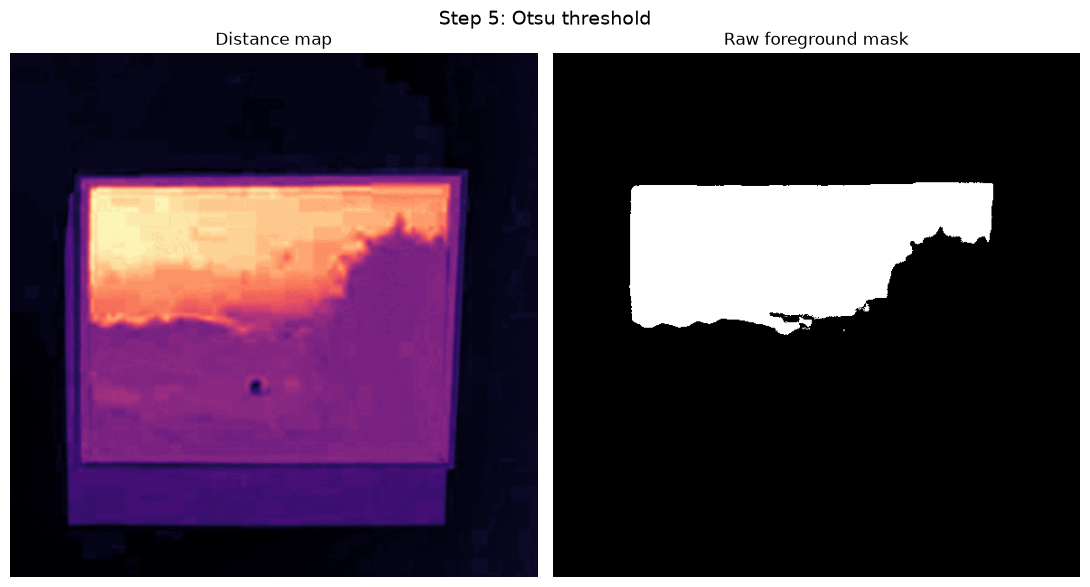

In [37]:
t, fg_raw = cv2.threshold(dist_u8, 0, 1, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("Otsu threshold:", t)
show_pair(dist_u8, fg_raw, "Distance map", "Raw foreground mask",
          cmap_b="magma", cmap_a="gray", suptitle="Step 5: Otsu threshold")


## 6. Morphological clean-up
Close fills holes inside the painting; open removes small blobs (e.g. the wall label).

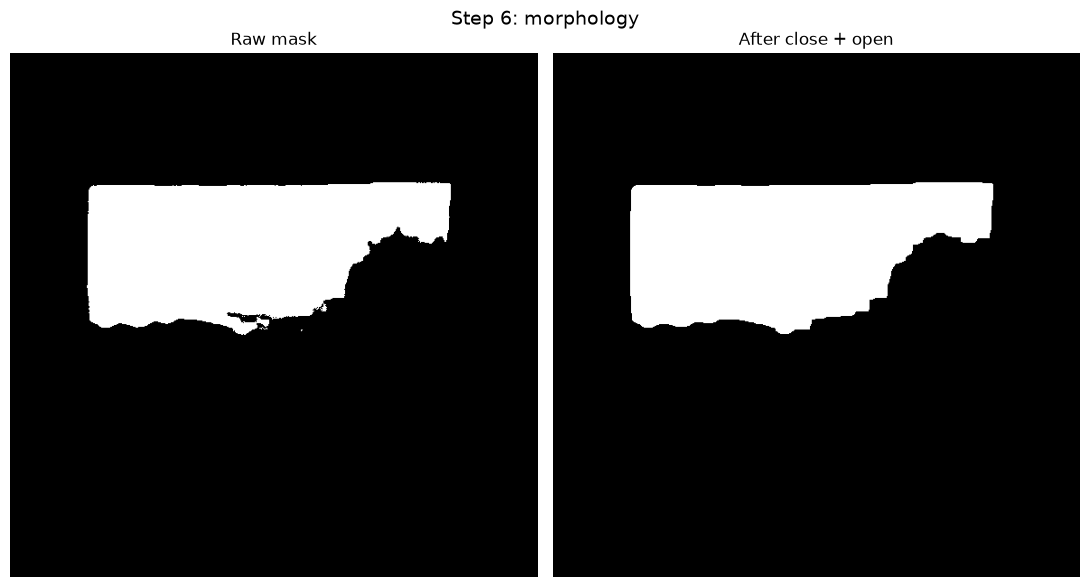

In [38]:
k = cv2.getStructuringElement(cv2.MORPH_RECT, (9, 9))
fg_clean = cv2.morphologyEx(fg_raw, cv2.MORPH_CLOSE, k)
fg_clean = cv2.morphologyEx(fg_clean, cv2.MORPH_OPEN, k)
show_pair(fg_raw, fg_clean, "Raw mask", "After close + open", "gray", "gray",
          suptitle="Step 6: morphology")


## 7. Force a rectangle (row / column projections, no contours)

In [39]:
cols = fg_clean.mean(axis=0) > PROJ_FRAC
rows = fg_clean.mean(axis=1) > PROJ_FRAC
x0, x1 = np.where(cols)[0][[0, -1]]
y0, y1 = np.where(rows)[0][[0, -1]]
pred = np.zeros((H, W), np.uint8)
pred[y0:y1 + 1, x0:x1 + 1] = 1
print(f"Rectangle: x[{x0}, {x1}]  y[{y0}, {y1}]")

fig, ax = plt.subplots(1, 3, figsize=(16, 6))
ax[0].imshow(fg_clean, cmap="gray"); ax[0].set_title("Cleaned mask")
ax[1].plot(fg_clean.mean(axis=0)); ax[1].axhline(PROJ_FRAC, color="r", ls="--")
ax[1].plot(fg_clean.mean(axis=1), alpha=0.7); ax[1].set_title("Column (blue) / row (orange) fraction of foreground")
ax[2].imshow(pred, cmap="gray"); ax[2].set_title("Final rectangular mask")
for a in (ax[0], ax[2]): a.axis("off")
fig.suptitle("Step 7: rectangle from projections", fontsize=14); plt.tight_layout(); plt.show()


IndexError: index 0 is out of bounds for axis 0 with size 0

## 8. Result: foreground extracted with the predicted mask

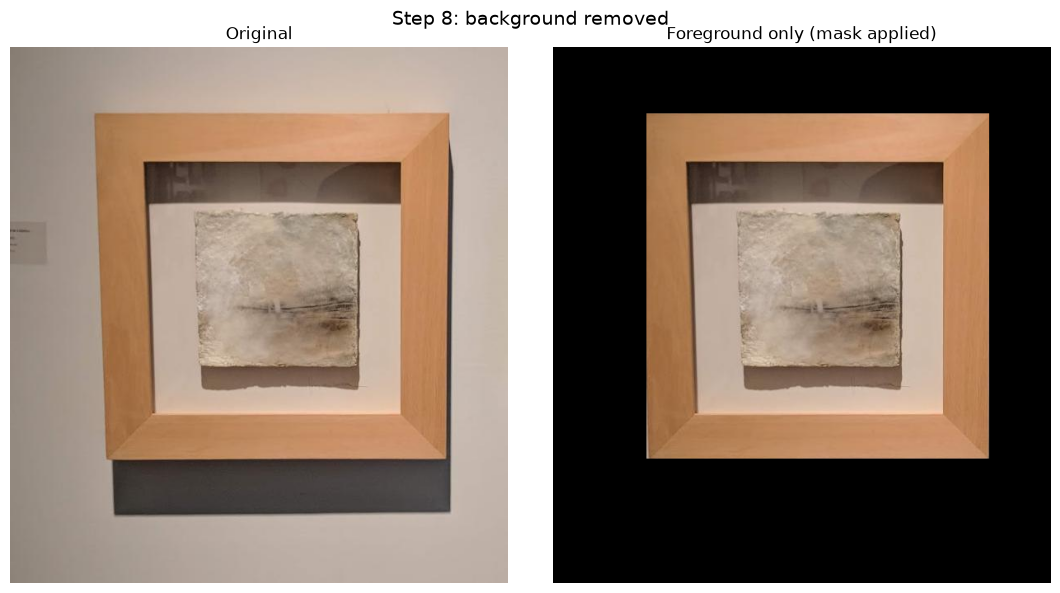

In [ ]:
result = img.copy(); result[pred == 0] = 0
show_pair(rgb(img), rgb(result), "Original", "Foreground only (mask applied)", suptitle="Step 8: background removed")


## 9. Predicted mask vs ground truth
Overlay colors: **green** = true positive, **red** = false positive (predicted but not painting), **blue** = false negative (missed painting).

Precision: 0.9991   Recall: 0.9779   F1: 0.9884


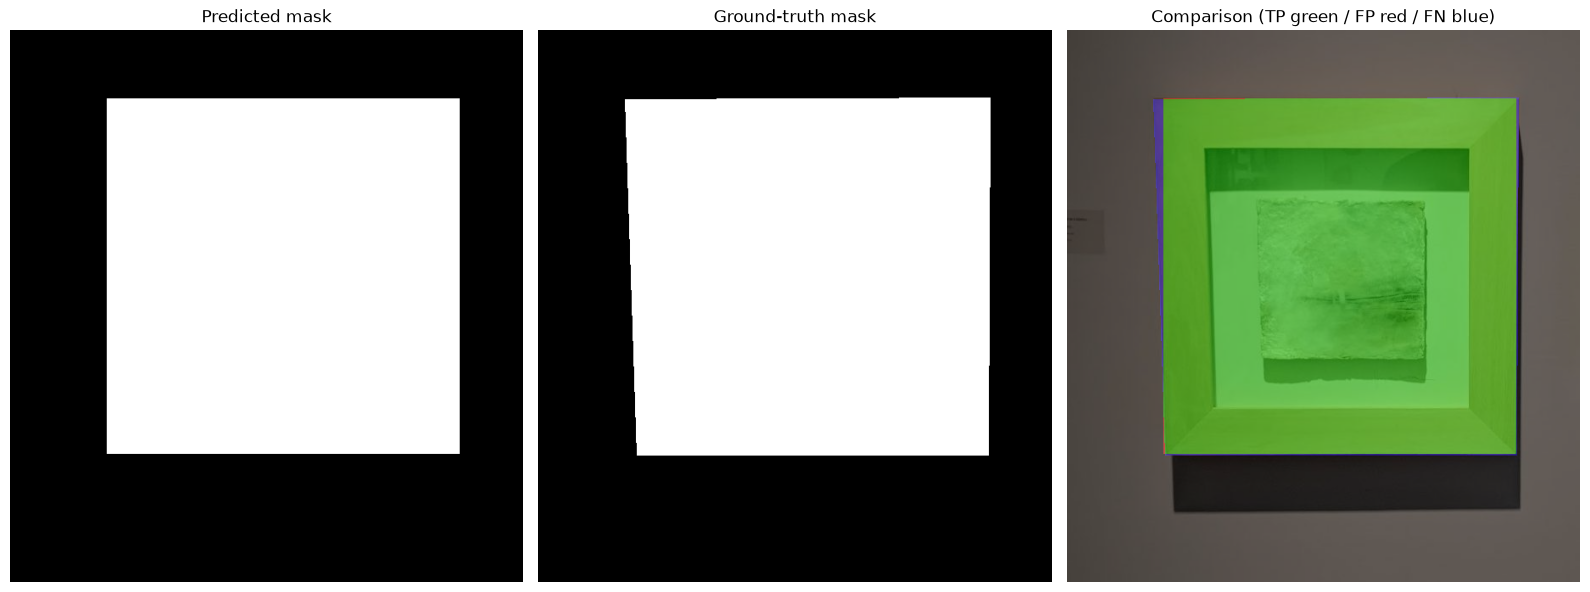

In [ ]:
def evaluate(pred, gt):
    pred, gt = pred.astype(bool), gt.astype(bool)
    tp = (pred & gt).sum(); fp = (pred & ~gt).sum(); fn = (~pred & gt).sum()
    p = tp / (tp + fp + 1e-9); r = tp / (tp + fn + 1e-9)
    return p, r, 2 * p * r / (p + r + 1e-9)

if os.path.exists(GT_PATH):
    gt = (cv2.imread(GT_PATH, 0) > 127).astype(np.uint8)
    if gt.shape != pred.shape:
        gt = cv2.resize(gt, (W, H), interpolation=cv2.INTER_NEAREST)

    p, r, f1 = evaluate(pred, gt)
    print(f"Precision: {p:.4f}   Recall: {r:.4f}   F1: {f1:.4f}")

    diffimg = np.zeros((H, W, 3), np.uint8)
    diffimg[(pred == 1) & (gt == 1)] = (0, 200, 0)
    diffimg[(pred == 1) & (gt == 0)] = (220, 0, 0)
    diffimg[(pred == 0) & (gt == 1)] = (0, 0, 220)

    fig, ax = plt.subplots(1, 3, figsize=(16, 7))
    ax[0].imshow(pred, cmap="gray"); ax[0].set_title("Predicted mask")
    ax[1].imshow(gt, cmap="gray");   ax[1].set_title("Ground-truth mask")
    ax[2].imshow(rgb(img)); ax[2].imshow(diffimg, alpha=0.5); ax[2].set_title("Comparison (TP green / FP red / FN blue)")
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()
else:
    print(f"Ground truth not found at {GT_PATH} – set GT_PATH to compare. Showing the prediction only.")
    show_pair(rgb(img), pred, "Original", "Predicted mask", cmap_a="gray")
